In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 160)
OUT = ROOT / "outputs"
def show(name): display(Image(filename=str(OUT / "figures" / f"{name}.png")))


# 05 Random Forest (and optional XGBoost) forecasting

In [2]:
pd.read_csv(OUT / "tables" / "forecast_accuracy.csv", index_col=0).round(4)

,n,RMSE,MAE,QLIKE,bias
historical_vol,8405.0,0.0775,0.0504,0.4631,0.0070
garch,8405.0,0.0713,0.0480,0.3902,0.0116
random_forest,8405.0,0.0770,0.0444,0.3994,-0.0003
xgboost,8405.0,0.0809,0.0479,0.4054,0.0061


In [3]:
pd.read_csv(OUT / 'tables' / 'diebold_mariano.csv').round(4)

,model_A,model_B,loss,mean_loss_diff,dm_stat,p_value,n
0,random_forest,historical_vol,QLIKE,-0.0637,-3.1182,0.0018,8405
1,random_forest,historical_vol,SqErr,-0.0001,-0.1850,0.8532,8405
2,random_forest,garch,QLIKE,0.0092,0.4994,0.6175,8405
3,random_forest,garch,SqErr,0.0008,1.5994,0.1098,8405
4,garch,historical_vol,QLIKE,-0.0729,-5.6817,0.0000,8405
5,garch,historical_vol,SqErr,-0.0009,-3.5784,0.0003,8405
6,xgboost,historical_vol,QLIKE,-0.0576,-3.1680,0.0015,8405
7,xgboost,historical_vol,SqErr,0.0005,1.1776,0.2390,8405
8,xgboost,garch,QLIKE,0.0153,0.9800,0.3271,8405
9,xgboost,garch,SqErr,0.0015,2.9886,0.0028,8405


In [4]:
pd.read_csv(OUT / 'tables' / 'forecast_accuracy_by_regime.csv').round(4)

,model,n,RMSE,MAE,QLIKE,bias,regime
0,historical_vol,1510.0,0.1316,0.0882,0.3787,0.0153,stress
1,garch,1510.0,0.1167,0.0789,0.3390,0.0084,stress
2,random_forest,1510.0,0.1450,0.0855,0.5633,-0.0113,stress
3,xgboost,1510.0,0.1533,0.0941,0.4990,0.0086,stress
4,historical_vol,6895.0,0.0594,0.0421,0.4816,0.0052,calm
5,garch,6895.0,0.0567,0.0412,0.4014,0.0123,calm
6,random_forest,6895.0,0.0512,0.0354,0.3635,0.0022,calm
7,xgboost,6895.0,0.0531,0.0378,0.3850,0.0055,calm


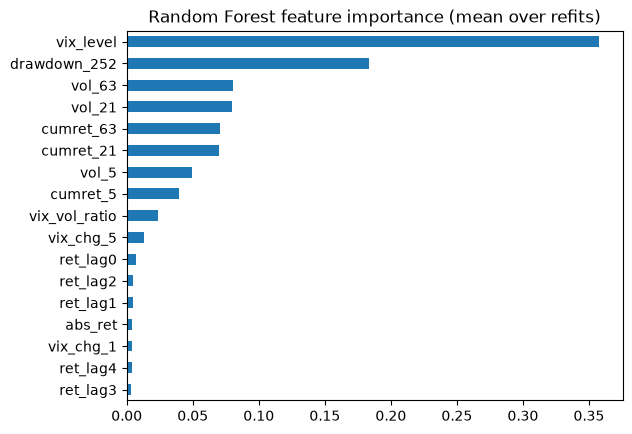

In [5]:
imp = pd.read_csv(OUT / "forecasts" / "rf_feature_importance_main.csv", index_col=0)["importance"]
imp.sort_values().plot.barh(title="Random Forest feature importance (mean over refits)")
plt.show()

In [6]:
log = pd.read_csv(OUT / "forecasts" / "rf_fit_log_main.csv", parse_dates=["origin_date", "train_start", "train_end"])
print("max train_end - origin gap (days):", (log.origin_date - log.train_end).dt.days.min(), "(label embargo: >= 5 trading days)")
log[["max_depth", "min_samples_leaf"]].value_counts()

max train_end - origin gap (days): 7 (label embargo: >= 5 trading days)


max_depth  min_samples_leaf
4          20                  228
8          20                  101
4          60                   72
Name: count, dtype: int64

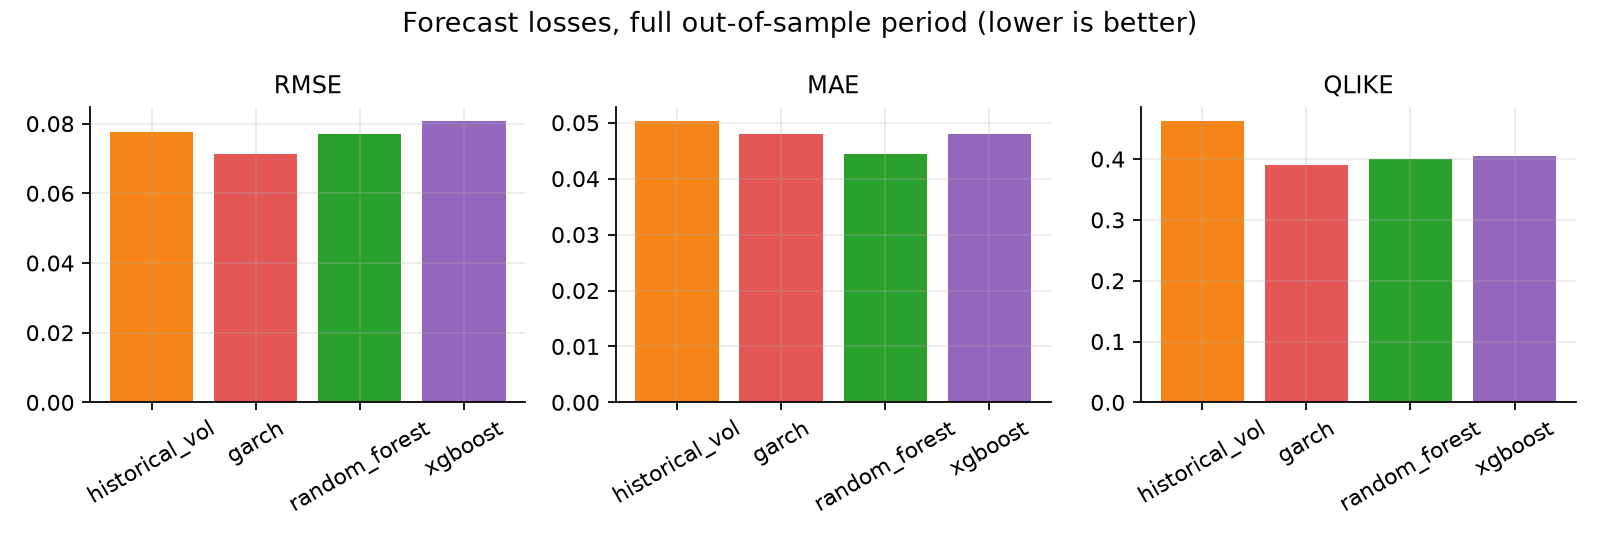

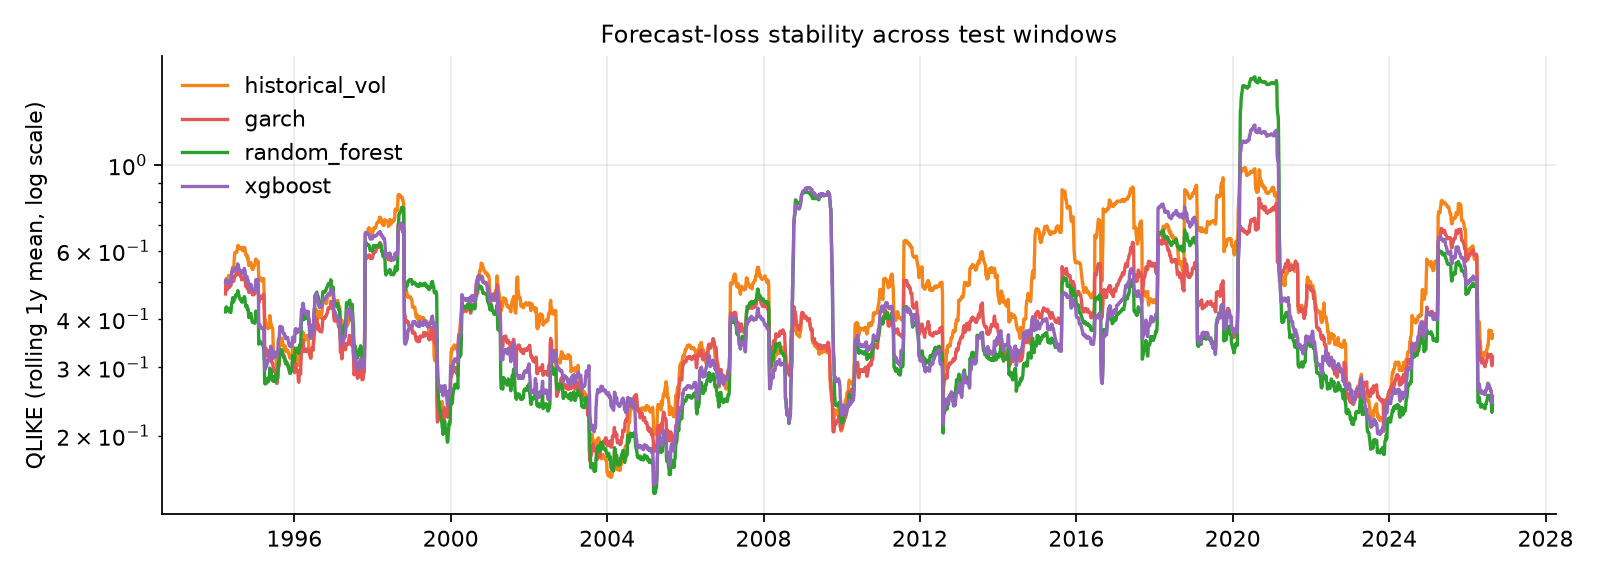

In [7]:
show('fig_forecast_loss'); show('fig_rolling_qlike')